# 02 - Exploratory analysis: where does revenue come from?

**Question.** How is revenue growing, when do customers buy, which categories and regions
drive it, and how concentrated is it?

**Method.** Named SQL queries from `sql/analysis_queries.sql` (CTEs and window functions)
run against the SQLite database. Net revenue = quantity x unit price x (1 - discount),
on delivered orders. Refunds are reported separately.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().resolve().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import metrics, plots
from src.common import load_config, project_path

cfg = load_config()
conn = metrics.open_db(cfg)
FIGURES = project_path(cfg["paths"]["figures_dir"])
pd.set_option("display.float_format", "{:,.2f}".format)
plots.apply_style()

## Headline numbers

In [2]:
metrics.run_query(conn, "kpi_summary").T.rename(columns={0: "value"})

,value
net_revenue_bdt,"17,920,829.00"
delivered_orders,"3,903.00"
buying_customers,"1,208.00"
avg_order_value_bdt,"4,591.55"
refunds_bdt,"1,486,455.50"
refunds_pct_of_revenue,8.29
cancelled_orders_pct,1.81


## Growth

,year,revenue,orders,buyers,avg_order_value,yoy_growth_pct
0,2023,"4,600,606.50",1026,438,"4,484.02",NaN
1,2024,"5,832,515.00",1231,472,"4,738.03",26.80
2,2025,"7,487,707.50",1646,614,"4,549.03",28.40


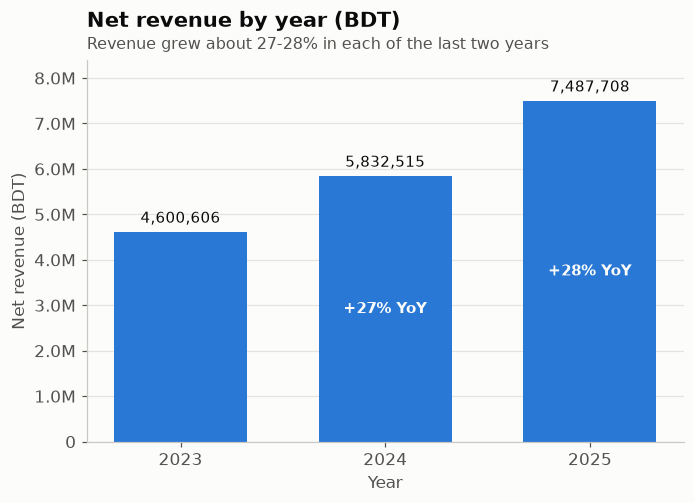

In [3]:
yearly = metrics.run_query(conn, "yearly_revenue")
display(yearly)

fig, ax = plots.new_figure(7, 4.5)
plots.bar_chart(ax, yearly["year"].astype(str).tolist(), yearly["revenue"].to_numpy(),
                value_format="{:,.0f}", horizontal=False)
ax.bar_label(ax.containers[0], labels=[""] + [f"+{g:.0f}% YoY" for g in yearly["yoy_growth_pct"].iloc[1:]],
             label_type="center", color=plots.SURFACE, fontsize=10, fontweight="bold")
plots.format_axis(ax, "y", "bdt")
plots.set_titles(ax, "Net revenue by year (BDT)", "Revenue grew about 27-28% in each of the last two years")
ax.set_xlabel("Year")
ax.set_ylabel("Net revenue (BDT)")
plots.save_figure(fig, FIGURES / "02_revenue_by_year.png")
plt.show()

Growth comes from more buyers, not bigger baskets: buyers rose from 438 to 614 while
average order value stayed in a narrow 4,480-4,740 BDT band.

## Seasonality

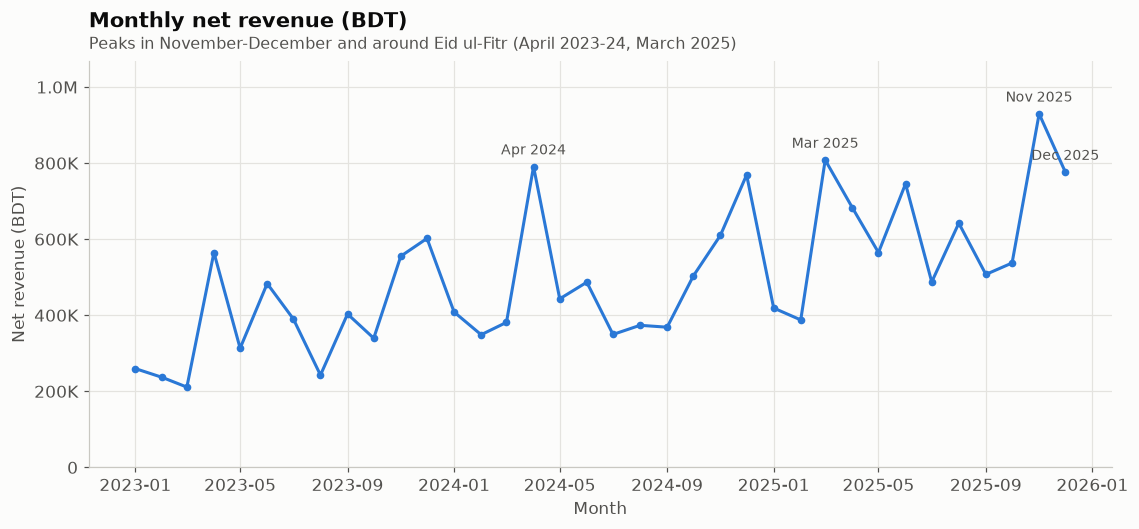

In [4]:
monthly = metrics.run_query(conn, "monthly_revenue")
monthly["month_start"] = pd.to_datetime(monthly["month"])

fig, ax = plots.new_figure(12, 4.8)
ax.plot(monthly["month_start"], monthly["revenue"], color=plots.SERIES[0], marker="o", markersize=4)
peaks = monthly.nlargest(4, "revenue")
for _, row in peaks.iterrows():
    ax.annotate(row["month_start"].strftime("%b %Y"), (row["month_start"], row["revenue"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=plots.TEXT_SECONDARY)
plots.format_axis(ax, "y", "bdt")
ax.set_ylim(0, monthly["revenue"].max() * 1.15)
plots.set_titles(ax, "Monthly net revenue (BDT)", "Peaks in November-December and around Eid ul-Fitr (April 2023-24, March 2025)")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (BDT)")
plots.save_figure(fig, FIGURES / "02_monthly_revenue.png")
plt.show()

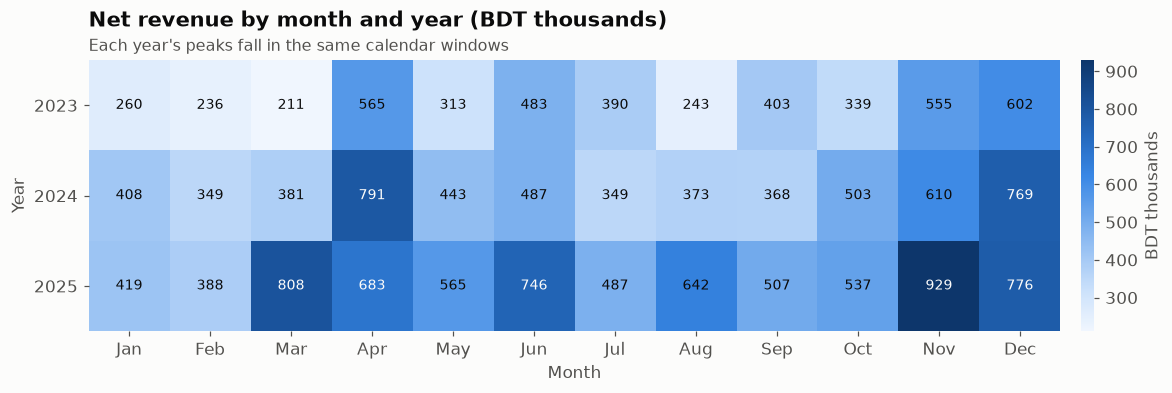

November + December share of annual revenue: 23.7% (2 of 12 months = 16.7%)


In [5]:
grid = monthly.assign(year=monthly["month_start"].dt.year, month=monthly["month_start"].dt.strftime("%b"))
grid = grid.pivot(index="year", columns="month", values="revenue")
grid = grid[pd.date_range("2024-01-01", periods=12, freq="MS").strftime("%b")] / 1000

fig, ax = plots.new_figure(12, 3.2)
plots.heatmap(ax, grid, value_format="{:,.0f}", colorbar_label="BDT thousands")
plots.set_titles(ax, "Net revenue by month and year (BDT thousands)", "Each year's peaks fall in the same calendar windows")
ax.set_xlabel("Month")
ax.set_ylabel("Year")
plots.save_figure(fig, FIGURES / "02_revenue_month_year.png")
plt.show()

month_share = monthly.groupby(monthly["month_start"].dt.month)["revenue"].sum() / monthly["revenue"].sum()
print(f"November + December share of annual revenue: {month_share.loc[[11, 12]].sum():.1%} (2 of 12 months = 16.7%)")

## When customers order

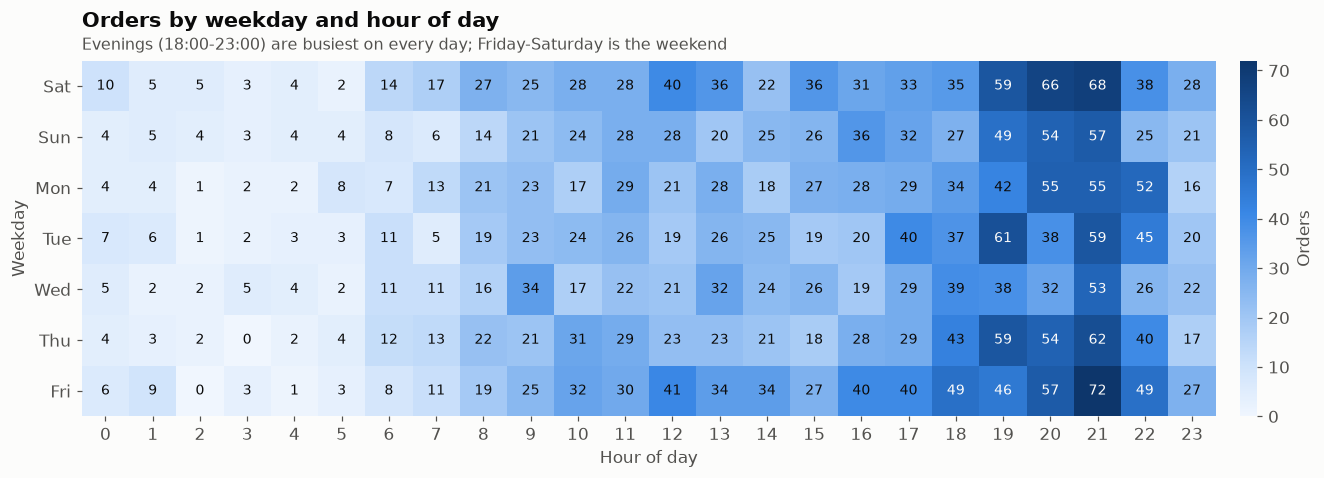

Orders per day: weekend 4.24 vs weekday 3.38 (+25%)
Share of orders placed 18:00-23:59: 45.9%


In [6]:
timing = metrics.run_query(conn, "weekday_hour_orders")
weekday_names = {0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"}
timing["weekday"] = timing["weekday"].map(weekday_names)
matrix = timing.pivot(index="weekday", columns="hour", values="orders").fillna(0)
matrix = matrix.loc[["Sat", "Sun", "Mon", "Tue", "Wed", "Thu", "Fri"]]

fig, ax = plots.new_figure(14, 4.2)
plots.heatmap(ax, matrix, value_format="{:.0f}", colorbar_label="Orders")
plots.set_titles(ax, "Orders by weekday and hour of day", "Evenings (18:00-23:00) are busiest on every day; Friday-Saturday is the weekend")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Weekday")
plots.save_figure(fig, FIGURES / "02_orders_weekday_hour.png")
plt.show()

days = pd.Series(pd.date_range(cfg["dates"]["start"], cfg["dates"]["end"])).dt.strftime("%a").value_counts()
per_day = matrix.sum(axis=1) / days.reindex(matrix.index)
weekend = per_day[["Fri", "Sat"]].mean()
weekday = per_day.drop(["Fri", "Sat"]).mean()
evening = matrix.loc[:, 18:23].to_numpy().sum() / matrix.to_numpy().sum()
print(f"Orders per day: weekend {weekend:.2f} vs weekday {weekday:.2f} (+{weekend / weekday - 1:.0%})")
print(f"Share of orders placed 18:00-23:59: {evening:.1%}")

## Categories

,revenue_rank,category_name,revenue,revenue_share_pct,units,lines,return_rate_pct,refunds
0,1,Electronics,"4,501,813.50",25.10,696,676,6.10,"246,042.00"
1,2,Fashion,"2,599,086.00",14.50,2090,1740,18.60,"493,850.00"
2,3,Sports & Outdoors,"2,397,686.50",13.40,652,597,5.20,"152,326.50"
3,4,Beauty & Personal Care,"1,985,164.00",11.10,1747,1267,3.60,"76,079.00"
4,5,Mobile & Accessories,"1,823,782.00",10.20,529,470,5.70,"145,024.50"
5,6,Home & Kitchen,"1,726,920.00",9.60,1514,1157,4.80,"87,711.00"
6,7,Footwear,"1,477,982.00",8.20,695,662,16.30,"259,967.00"
7,8,Groceries,"544,478.00",3.00,1859,727,1.40,"6,420.00"
8,9,Books & Stationery,"434,275.50",2.40,1043,829,1.80,"7,356.50"
9,10,Toys & Baby,"429,641.50",2.40,494,386,4.40,"11,679.00"


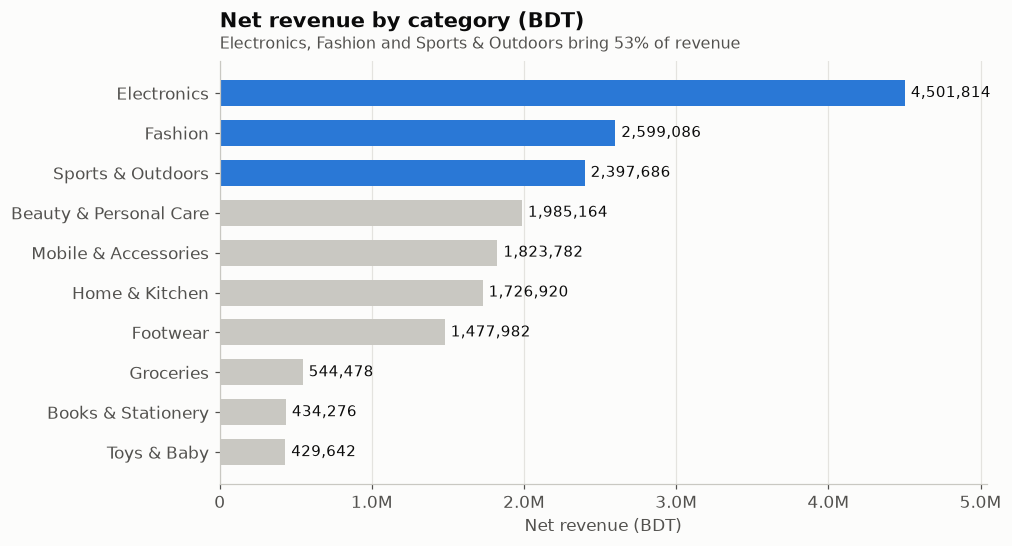

In [7]:
categories = metrics.run_query(conn, "category_performance")
display(categories)

fig, ax = plots.new_figure(9, 5)
plots.bar_chart(ax, categories["category_name"].tolist(), categories["revenue"].to_numpy(),
                value_format="{:,.0f}", highlight=categories["category_name"].head(3).tolist())
plots.format_axis(ax, "x", "bdt")
plots.set_titles(ax, "Net revenue by category (BDT)", "Electronics, Fashion and Sports & Outdoors bring 53% of revenue")
ax.set_xlabel("Net revenue (BDT)")
plots.save_figure(fig, FIGURES / "02_category_revenue.png")
plt.show()

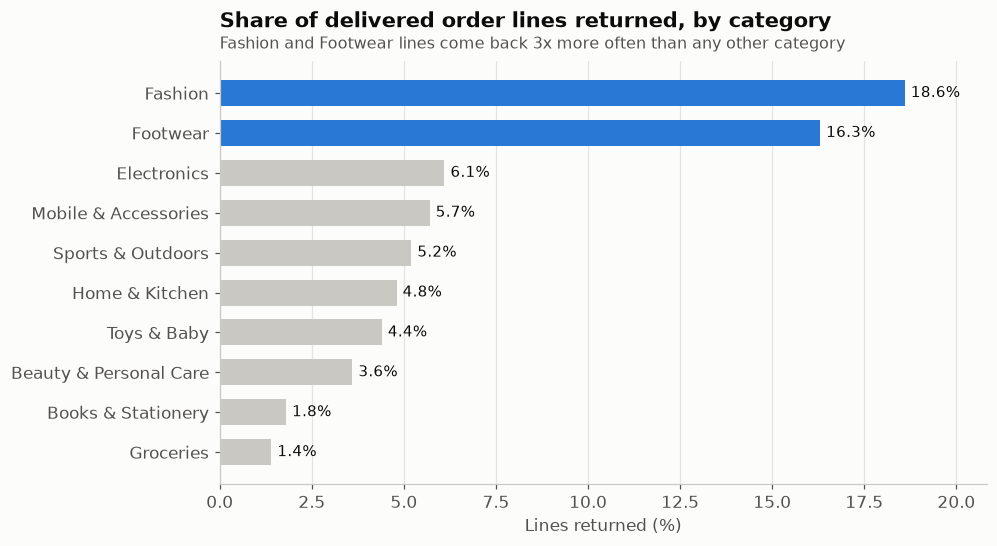

Fashion + Footwear: 22.7% of revenue, 51% of all refunds


In [8]:
by_returns = categories.sort_values("return_rate_pct", ascending=False)
fig, ax = plots.new_figure(9, 5)
plots.bar_chart(ax, by_returns["category_name"].tolist(), by_returns["return_rate_pct"].to_numpy(),
                value_format="{:.1f}%", highlight=["Fashion", "Footwear"])
plots.set_titles(ax, "Share of delivered order lines returned, by category", "Fashion and Footwear lines come back 3x more often than any other category")
ax.set_xlabel("Lines returned (%)")
plots.save_figure(fig, FIGURES / "02_category_returns.png")
plt.show()

fashion = categories.set_index("category_name").loc[["Fashion", "Footwear"]]
print(f"Fashion + Footwear: {fashion['revenue_share_pct'].sum():.1f}% of revenue, "
      f"{fashion['refunds'].sum() / categories['refunds'].sum():.0%} of all refunds")

In [9]:
ranks = metrics.run_query(conn, "category_rank_by_year").pivot(index="category_name", columns="year", values="rank_in_year")
ranks.sort_values(ranks.columns[-1])

year,2023,2024,2025
category_name,,,
Electronics,1,1,1
Fashion,3,2,2
Sports & Outdoors,2,4,3
Beauty & Personal Care,4,5,4
Home & Kitchen,5,6,5
Mobile & Accessories,6,3,6
Footwear,7,7,7
Groceries,8,8,8
Books & Stationery,10,9,9


## Order value

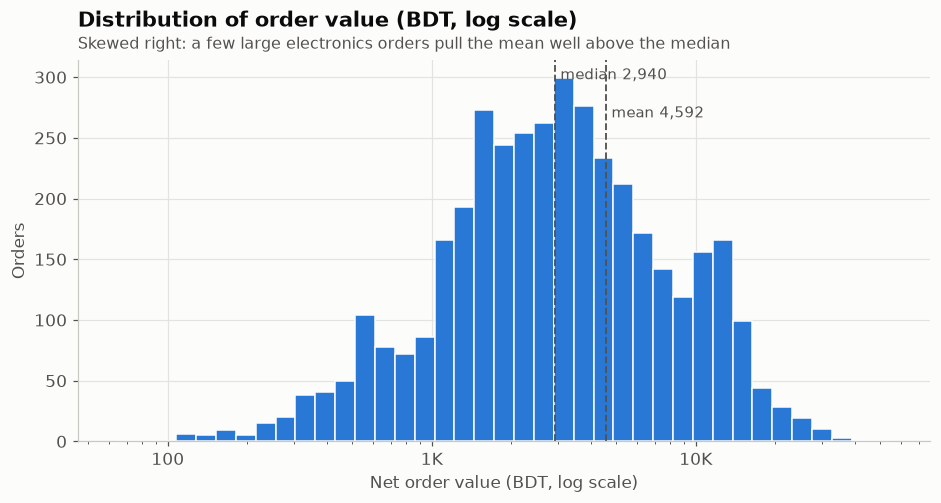

count    3,903.00
mean     4,591.55
std      4,773.43
min         64.00
25%      1,540.00
50%      2,940.00
75%      5,730.00
90%     11,370.00
99%     22,545.60
max     55,270.00
Name: net_revenue, dtype: float64

In [10]:
orders = metrics.run_query(conn, "order_revenue")
values = orders["net_revenue"]
bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 40)

fig, ax = plots.new_figure(10, 4.5)
ax.hist(values, bins=bins, color=plots.SERIES[0], edgecolor=plots.SURFACE, linewidth=1)
ax.set_xscale("log")
for stat, label, offset in [(values.median(), "median", 0.95), (values.mean(), "mean", 0.85)]:
    ax.axvline(stat, color=plots.TEXT_SECONDARY, linewidth=1.2, linestyle="--")
    ax.text(stat, ax.get_ylim()[1] * offset, f" {label} {stat:,.0f}", color=plots.TEXT_SECONDARY, fontsize=10)
ax.xaxis.set_major_formatter(plt.FuncFormatter(plots.bdt))
plots.set_titles(ax, "Distribution of order value (BDT, log scale)", "Skewed right: a few large electronics orders pull the mean well above the median")
ax.set_xlabel("Net order value (BDT, log scale)")
ax.set_ylabel("Orders")
plots.save_figure(fig, FIGURES / "02_order_value_distribution.png")
plt.show()
values.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

## Geography

,division,buyers,orders,revenue,revenue_share_pct,avg_order_value,revenue_per_buyer
0,Dhaka,532,1664,"7,729,458.50",43.10,"4,645.11","14,529.06"
1,Chattogram,203,736,"3,268,445.50",18.20,"4,440.82","16,100.72"
2,Khulna,103,397,"1,964,963.50",11.00,"4,949.53","19,077.32"
3,Rajshahi,106,312,"1,387,406.00",7.70,"4,446.81","13,088.74"
4,Sylhet,83,282,"1,250,858.50",7.00,"4,435.67","15,070.58"
5,Rangpur,76,242,"1,133,649.00",6.30,"4,684.50","14,916.43"
6,Mymensingh,57,154,"643,549.50",3.60,"4,178.89","11,290.34"
7,Barishal,48,116,"542,498.50",3.00,"4,676.71","11,302.05"


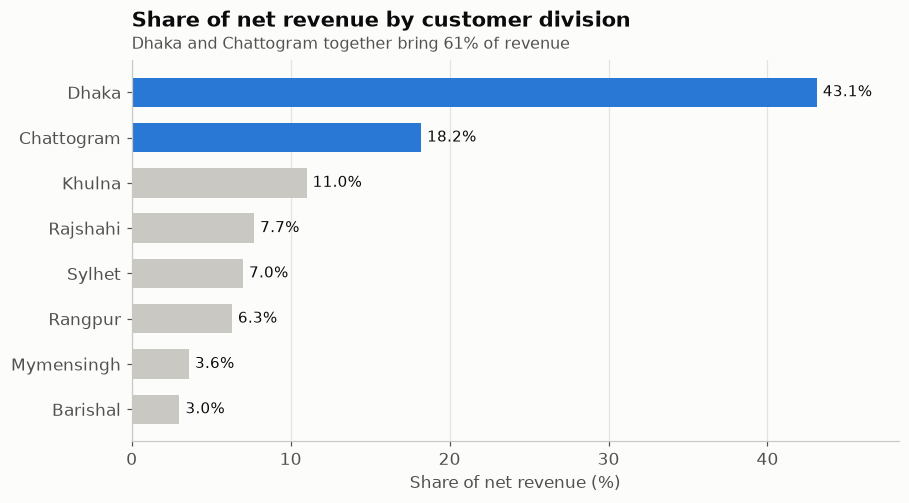

In [11]:
divisions = metrics.run_query(conn, "division_performance")
display(divisions)

fig, ax = plots.new_figure(9, 4.5)
plots.bar_chart(ax, divisions["division"].tolist(), divisions["revenue_share_pct"].to_numpy(),
                value_format="{:.1f}%", highlight=["Dhaka", "Chattogram"])
plots.set_titles(ax, "Share of net revenue by customer division", "Dhaka and Chattogram together bring 61% of revenue")
ax.set_xlabel("Share of net revenue (%)")
plots.save_figure(fig, FIGURES / "02_division_revenue.png")
plt.show()

Revenue per buyer ranges from about 11K BDT in Mymensingh and Barishal to 19K in Khulna.
With only 48-106 buyers in the smaller divisions, one or two large customers can move those
figures, so they should be read as directional.

## Concentration

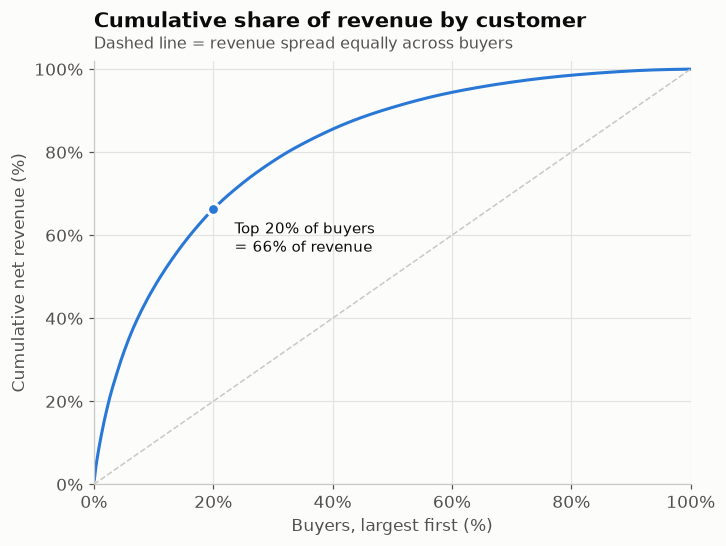

Top 20% of 1208 buyers: 66.3% of net revenue


In [12]:
customer_revenue = metrics.run_query(conn, "customer_summary").set_index("customer_id")["revenue"]
share = metrics.top_share(customer_revenue, cfg["analysis"]["pareto_top_share"])
curve = metrics.pareto_curve(customer_revenue)

fig, ax = plots.new_figure(7, 5)
ax.plot(curve["customer_share"], curve["revenue_share"], color=plots.SERIES[0])
ax.plot([0, 1], [0, 1], color=plots.MUTED, linewidth=1, linestyle="--")
ax.scatter([0.2], [share], color=plots.SERIES[0], s=60, zorder=3, edgecolor=plots.SURFACE, linewidth=2)
ax.annotate(f"Top 20% of buyers\n= {share:.0%} of revenue", (0.2, share), textcoords="offset points",
            xytext=(14, -28), fontsize=10)
plots.format_axis(ax, "x", "pct")
plots.format_axis(ax, "y", "pct")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
plots.set_titles(ax, "Cumulative share of revenue by customer", "Dashed line = revenue spread equally across buyers")
ax.set_xlabel("Buyers, largest first (%)")
ax.set_ylabel("Cumulative net revenue (%)")
plots.save_figure(fig, FIGURES / "02_pareto_curve.png")
plt.show()
print(f"Top 20% of {len(customer_revenue)} buyers: {share:.1%} of net revenue")

## Payment methods

In [13]:
metrics.run_query(conn, "payment_method_mix")

,payment_method,orders,order_share_pct,failure_rate_pct,collected_bdt
0,cash_on_delivery,1797,45.20,1.56,"7,872,609.50"
1,bkash,1104,27.80,1.99,"5,078,710.50"
2,card,478,12.00,2.30,"2,162,257.50"
3,nagad,418,10.50,1.67,"2,020,279.50"
4,bank_transfer,178,4.50,2.25,"837,301.00"


## Findings

- **Growth:** net revenue grew 26.8% in 2024 and 28.4% in 2025, to 7.49M BDT. Growth came
  from more buyers (+40% over two years) while average order value stayed flat at about
  4,500 BDT.
- **Seasonality:** November and December bring 23.7% of annual revenue, against 16.7%
  if revenue were spread evenly. The Eid
  ul-Fitr shopping window (April in 2023-24, late March in 2025) is the other recurring peak.
- **Timing:** Friday and Saturday, the Bangladeshi weekend, see about a quarter more orders
  per day than other days. Close to half of all orders arrive after 18:00.
- **Categories:** Electronics is the largest category (25% of revenue). Fashion and Footwear
  have by far the highest return rates (16-19% of lines) and generate half of all refunds
  from under a quarter of revenue.
- **Geography:** Dhaka division alone brings 43% of revenue, Chattogram 18%.
- **Concentration:** the top 20% of buyers produce 66% of revenue, a classic Pareto pattern.
- **Payments:** cash on delivery is still 45% of orders, with bKash second at 28%.